<a href="https://colab.research.google.com/github/CodeWiz04/docvqa-layout-fusion/blob/main/docvqa_layout_fusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Layout-Guided Multimodal Fusion for Document VQA: full pipeline notebook

Single notebook, run top to bottom (Colab, GPU runtime).

| Part | Contents | Owner |
|---|---|---|
| 1 | Data loading, preprocessing, loaders, statistics (1,200-question DocVQA subset) | Person 1 |
| 2 | Evaluation metrics (ANLS, RA, ANLSL, BLEU-4), bootstrap CIs, `evaluate()` | Person 1 |
| 3+ | Backbone and baselines V1-V4, proposed fusion V5, training, results (appended next) | Persons 2 and 3 |

# Part 1: Data preparation and preprocessing (1,200-question DocVQA subset)

Dataset: `nielsr/docvqa_1200_examples` (148 MB; 1,000 train + 200 test; each row has the page image, OCR words, word boxes, question and answers). Colab downloads it from Hugging Face, so nothing needs uploading.

**Before running:** Runtime -> Change runtime type -> GPU (T4). Then Runtime -> Run all.

Pipeline: load -> split (800 train / 200 val / 200 test) -> normalise boxes to 0-1000 -> tokenise `[CLS] question [SEP] OCR [SEP]` with a box per sub-word -> answer-span matching -> resize/pad image -> DataLoaders -> visual check -> dataset statistics.

## 1. Install and settings

In [1]:
# [colab-only]
!pip -q install datasets transformers sacrebleu
import torch
print("torch", torch.__version__, "| GPU available:", torch.cuda.is_available())

torch 2.11.0+cu130 | GPU available: True


In [2]:
import random, re, string
from dataclasses import dataclass

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import matplotlib.pyplot as plt
import matplotlib.patches as patches


@dataclass
class Config:
    dataset_name: str = "nielsr/docvqa_1200_examples"
    val_size: int = 200            # carved out of the 1,000 training rows -> 800 train / 200 val
    img_size: int = 512            # longer side resized to this, then padded to a square
    patch_size: int = 16           # ViT patch size -> (512/16)^2 = 1024 patches
    img_mean: tuple = (0.5, 0.5, 0.5)
    img_std: tuple = (0.5, 0.5, 0.5)
    tokenizer_name: str = "bert-base-uncased"
    max_seq_len: int = 512         # question + OCR tokens + 3 special tokens
    max_answer_len: int = 32       # target length for the answer head
    box_grid: int = 1000           # boxes normalised to a 0..1000 integer grid
    batch_size: int = 8
    num_workers: int = 2
    seed: int = 42


CFG = Config()


def set_seed(seed=CFG.seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


set_seed()

## 2. Load the dataset and inspect it
Look at the printed fields first. The code below assumes the columns listed on the Hugging Face page: `image`, `query` (dict of languages), `answers`, `words`, `bounding_boxes`.

In [3]:
# [colab-only]
from datasets import load_dataset
raw = load_dataset(CFG.dataset_name)
print(raw)
print(raw["train"].features)

ex = raw["train"][0]
print("\nquestion:", ex["query"])
print("answers :", ex["answers"])
print("n words :", len(ex["words"]), "| first words:", ex["words"][:5])
print("first boxes:", ex["bounding_boxes"][:3])
print("image size:", ex["image"].size)

dataset_infos.json:   0%|          | 0.00/1.74k [00:00<?, ?B/s]

data/train-00000-of-00001-f795527aa19f0f(…): reconstructing file:   0%|          |  0.00B /  123MB            

data/train-00000-of-00001-f795527aa19f0f(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-41a63b2e1b4ecc5(…): reconstructing file:   0%|          |  0.00B / 25.2MB            

data/test-00000-of-00001-41a63b2e1b4ecc5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/200 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'image', 'query', 'answers', 'words', 'bounding_boxes', 'answer'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['id', 'image', 'query', 'answers', 'words', 'bounding_boxes', 'answer'],
        num_rows: 200
    })
})
{'id': Value('string'), 'image': Image(mode=None, decode=True), 'query': {'de': Value('string'), 'en': Value('string'), 'es': Value('string'), 'fr': Value('string'), 'it': Value('string')}, 'answers': List(Value('string')), 'words': List(Value('string')), 'bounding_boxes': List(List(Value('float32'), length=4)), 'answer': {'match_score': Value('float64'), 'matched_text': Value('string'), 'start': Value('int64'), 'text': Value('string')}}

question: {'de': 'Wie lautet das Datum, das in diesem Brief erwähnt wird?', 'en': 'what is the date mentioned in this letter?', 'es': '¿Cuál es la fecha mencionada en esta carta?', 'fr': 'Quelle est la date mentionnée dans cette lettre?', 'it': 'Qual è la 

## 3. Split: 800 train / 200 val / 200 test
The dataset has no validation split, so 200 rows are held out of the training rows (fixed seed) for early stopping.

In [4]:
split = raw["train"].train_test_split(test_size=CFG.val_size, seed=CFG.seed)
splits = {"train": split["train"], "val": split["test"], "test": raw["test"]}
print({k: len(v) for k, v in splits.items()})

{'train': 800, 'val': 200, 'test': 200}


## 4. Text, box and answer helpers
* `normalize_text`: lower-case, strip punctuation (used for answer matching).
* Boxes: the box scale of this dataset is not documented, so `detect_box_mode` checks it on 50 pages and converts everything to the 0-1000 grid. **Read the printed mode**; if it looks wrong, set `BOX_MODE` by hand to `"unit"` (values 0-1), `"norm1000"` (already 0-1000) or `"pixel"`.
* `find_answer_span`: finds an OCR word span matching a ground-truth answer (`-1, -1` if the answer is not an exact OCR span).

In [5]:
def normalize_text(s):
    s = s.lower().strip().translate(str.maketrans("", "", string.punctuation))
    return re.sub(r"\s+", " ", s)


def get_question(ex):
    q = ex["query"]
    if isinstance(q, dict):
        q = q.get("en") or next(v for v in q.values() if v)
    return q


def flatten_box(b):
    """Accept [x0,y0,x1,y1] or an 8-number quadrilateral; return [xmin,ymin,xmax,ymax]."""
    b = [float(v) for v in np.array(b).flatten()]
    if len(b) >= 8:
        xs, ys = b[0:8:2], b[1:8:2]
        return [min(xs), min(ys), max(xs), max(ys)]
    return b[:4]


def detect_box_mode(hf_split, n=100):
    """Pages differ in width, so the right-most OCR x is stable relative to the page width if boxes are in
    pixels, and stable relative to 1000 if they are already on the 0-1000 grid. Pick the steadier one."""
    r_pix, r_norm, max_all = [], [], 0.0
    for i in range(min(n, len(hf_split))):
        ex = hf_split[i]
        w, h = ex["image"].size
        if not len(ex["bounding_boxes"]):
            continue
        fb = [flatten_box(b) for b in ex["bounding_boxes"]]
        mx = max(b[2] for b in fb)
        max_all = max(max_all, max(max(b) for b in fb))
        r_pix.append(mx / w); r_norm.append(mx / 1000.0)
    if max_all <= 1.5:
        return "unit"
    cv = lambda a: float(np.std(a) / (np.mean(a) + 1e-9))
    print(f"spread of right-edge ratio: pixel={cv(r_pix):.3f}  norm1000={cv(r_norm):.3f}  (lower = better fit)")
    return "pixel" if cv(r_pix) < cv(r_norm) else "norm1000"


def to_grid(box, w, h, mode):
    x0, y0, x1, y1 = flatten_box(box)
    if mode == "unit":
        vals = [x0, y0, x1, y1]; vals = [v * CFG.box_grid for v in vals]
    elif mode == "norm1000":
        vals = [x0, y0, x1, y1]
    else:  # pixel
        vals = [x0 / w * CFG.box_grid, y0 / h * CFG.box_grid, x1 / w * CFG.box_grid, y1 / h * CFG.box_grid]
    return [int(min(max(v, 0), CFG.box_grid)) for v in vals]


BOX_MODE = detect_box_mode(splits["train"])
print("Detected box mode:", BOX_MODE)


def get_words_boxes(ex, w, h):
    words, boxes = [], []
    for word, box in zip(ex["words"], ex["bounding_boxes"]):
        if word is None or not str(word).strip():
            continue
        words.append(str(word))
        boxes.append(to_grid(box, w, h, BOX_MODE))
    return words, boxes


def find_answer_span(words, answers, max_ngram=12):
    targets = {normalize_text(a) for a in answers if a and a.strip()}
    norm_words = [normalize_text(w) for w in words]
    for n in range(1, max_ngram + 1):
        for i in range(len(words) - n + 1):
            if " ".join(norm_words[i:i + n]).strip() in targets:
                return i, i + n - 1
    return -1, -1

spread of right-edge ratio: pixel=0.255  norm1000=0.049  (lower = better fit)
Detected box mode: norm1000


## 5. Image transform
Longer side -> `img_size`, pasted top-left on a white square canvas, then normalised. Light augmentation (brightness/contrast, +-2 degree rotation, mild noise) is applied to the training split only; text and boxes are never augmented.

In [6]:
def build_image_transform(train):
    size = CFG.img_size

    def resize_pad(img):
        w, h = img.size
        scale = size / max(w, h)
        img = img.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.BICUBIC)
        canvas = Image.new("RGB", (size, size), (255, 255, 255))
        canvas.paste(img, (0, 0))
        return canvas

    class GaussianNoise:
        def __call__(self, x):
            return (x + torch.randn_like(x) * 0.02).clamp(0, 1)

    steps = [T.Lambda(resize_pad)]
    if train:
        steps += [T.ColorJitter(brightness=0.2, contrast=0.2), T.RandomRotation(2, fill=255),
                  T.ToTensor(), T.RandomApply([GaussianNoise()], p=0.3)]
    else:
        steps += [T.ToTensor()]
    steps += [T.Normalize(CFG.img_mean, CFG.img_std)]
    return T.Compose(steps)

## 6. Tokenizer

In [7]:
# [colab-only]
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(CFG.tokenizer_name)
print(type(tok).__name__, "| fast:", tok.is_fast)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BertTokenizer | fast: True


## 7. Dataset class
Each sample: `[CLS] question [SEP] OCR tokens [SEP]` padded to 512. Every sub-word inherits its word's box; question tokens get box `[0,0,0,0]`. Raw question and answers are kept for ANLS later.

In [8]:
class DocVQA1200(Dataset):
    def __init__(self, hf_split, tokenizer, train=False):
        self.hf, self.tok, self.train = hf_split, tokenizer, train
        self.transform = build_image_transform(train)

    def __len__(self):
        return len(self.hf)

    def get_raw_image(self, idx):
        return self.hf[idx]["image"].convert("RGB")

    def _encode(self, question, words, boxes):
        tok, L = self.tok, CFG.max_seq_len
        q_ids = tok(question, add_special_tokens=False, truncation=True, max_length=64)["input_ids"]
        if words:
            ocr = tok(words, is_split_into_words=True, add_special_tokens=False)
            ocr_ids, word_ids = ocr["input_ids"], ocr.word_ids()
        else:
            ocr_ids, word_ids = [], []
        budget = L - len(q_ids) - 3
        ocr_ids, word_ids = ocr_ids[:budget], word_ids[:budget]

        input_ids = [tok.cls_token_id] + q_ids + [tok.sep_token_id] + ocr_ids + [tok.sep_token_id]
        bbox = [[0, 0, 0, 0]] * (len(q_ids) + 2) + [boxes[w] for w in word_ids] + [[1000, 1000, 1000, 1000]]
        full_word_ids = [-1] * (len(q_ids) + 2) + list(word_ids) + [-1]

        pad = L - len(input_ids)
        attention_mask = [1] * len(input_ids) + [0] * pad
        input_ids += [tok.pad_token_id] * pad
        bbox += [[0, 0, 0, 0]] * pad
        full_word_ids += [-1] * pad
        return {"input_ids": torch.tensor(input_ids), "attention_mask": torch.tensor(attention_mask),
                "bbox": torch.tensor(bbox), "word_ids": full_word_ids}

    @staticmethod
    def _word_span_to_token_span(word_ids, w_start, w_end):
        if w_start < 0:
            return -1, -1
        pos = [i for i, w in enumerate(word_ids) if w_start <= w <= w_end]
        return (pos[0], pos[-1]) if pos else (-1, -1)

    def _text_features(self, ex, w, h):
        question = get_question(ex)
        words, boxes = get_words_boxes(ex, w, h)
        answers = [a for a in (ex.get("answers") or []) if a and str(a).strip()]
        enc = self._encode(question, words, boxes)
        ws, we = find_answer_span(words, answers) if answers else (-1, -1)
        st, en = self._word_span_to_token_span(enc["word_ids"], ws, we)
        return question, words, answers, enc, st, en

    def __getitem__(self, idx):
        ex = self.hf[idx]
        image = ex["image"].convert("RGB")
        w, h = image.size
        question, words, answers, enc, st, en = self._text_features(ex, w, h)

        target = self.tok(answers[0] if answers else "", add_special_tokens=True, truncation=True,
                          max_length=CFG.max_answer_len, padding="max_length", return_tensors="pt")["input_ids"][0]
        labels = target.clone()
        labels[labels == self.tok.pad_token_id] = -100       # ignored by cross-entropy

        return {
            "pixel_values": self.transform(image),            # (3, S, S)
            "input_ids": enc["input_ids"],                    # (L,)
            "attention_mask": enc["attention_mask"],          # (L,)
            "bbox": enc["bbox"],                              # (L, 4) on 0..1000
            "labels": labels,                                 # (A,)
            "start_positions": torch.tensor(st),              # -1 if not an exact OCR span
            "end_positions": torch.tensor(en),
            "index": idx,
            "question": question,
            "answers": answers,
        }

    def stats_row(self, idx):
        ex = self.hf[idx]
        w, h = ex["image"].size
        question, words, answers, enc, st, en = self._text_features(ex, w, h)
        return {"ocr_words": len(words), "tokens": int(enc["attention_mask"].sum()), "extractive": st >= 0}


def collate_fn(batch):
    out = {}
    for key in batch[0]:
        vals = [b[key] for b in batch]
        out[key] = torch.stack(vals) if isinstance(vals[0], torch.Tensor) else vals
    return out


def make_loader(ds, shuffle=False):
    return DataLoader(ds, batch_size=CFG.batch_size, shuffle=shuffle, num_workers=CFG.num_workers,
                      collate_fn=collate_fn, pin_memory=torch.cuda.is_available())

## 8. Build datasets and loaders, check one batch

In [9]:
datasets_ = {name: DocVQA1200(hf, tok, train=(name == "train")) for name, hf in splits.items()}
loaders = {name: make_loader(ds, shuffle=(name == "train")) for name, ds in datasets_.items()}

batch = next(iter(loaders["train"]))
for k, v in batch.items():
    print(f"{k:16s}", tuple(v.shape) if hasattr(v, "shape") else f"list[{len(v)}]")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (575 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (590 > 512). Running this sequence through the model will result in indexing errors


pixel_values     (8, 3, 512, 512)
input_ids        (8, 512)
attention_mask   (8, 512)
bbox             (8, 512, 4)
labels           (8, 32)
start_positions  (8,)
end_positions    (8,)
index            list[8]
question         list[8]
answers          list[8]


## 9. Visual check: raw page vs preprocessed page with OCR boxes
Red boxes are the OCR word boxes mapped onto the resized page. If they do not sit on the text, the box mode in section 4 is wrong. This is also the "raw vs preprocessed" figure for the report.

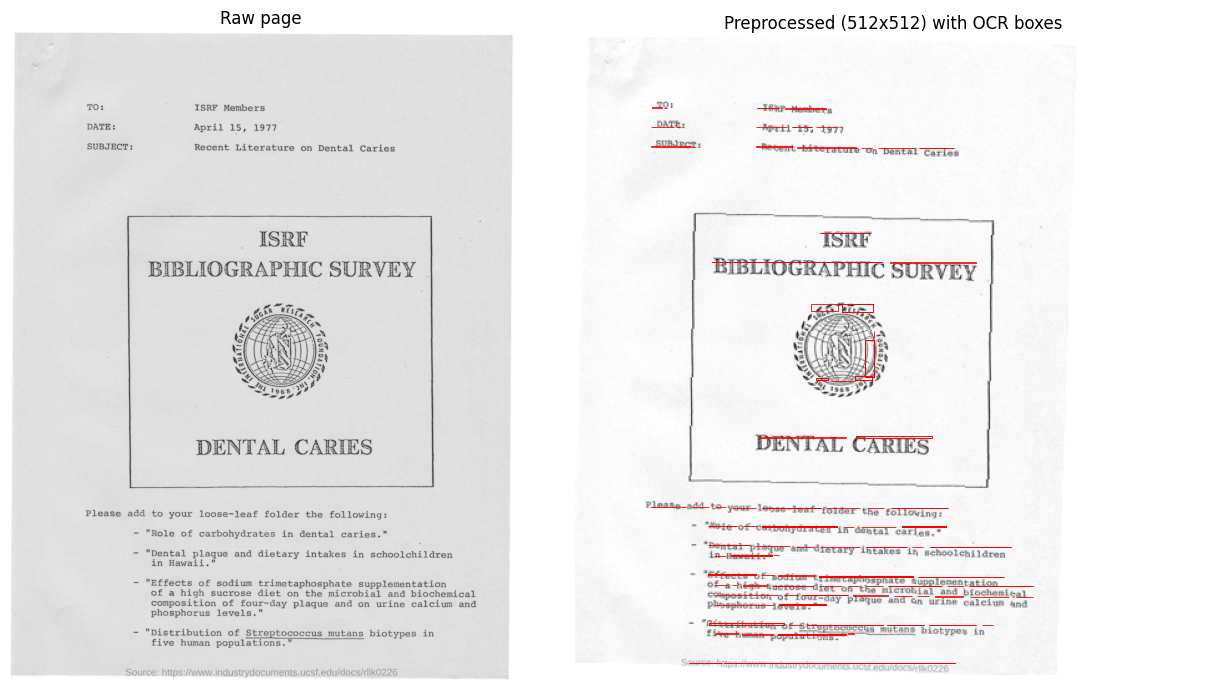

Question  : Which biotypes distribution is taken place in five human populations?
Answers   : ['streptococcus mutans', 'Streptococcus mutans']
Span found: streptococcus mutans


In [10]:
def denormalize(pv):
    mean = np.array(CFG.img_mean)[:, None, None]; std = np.array(CFG.img_std)[:, None, None]
    return np.clip((pv.numpy() * std + mean).transpose(1, 2, 0), 0, 1)


def show_sample(ds, idx, max_boxes=600, save_path=None):
    s = ds[idx]
    raw_img = ds.get_raw_image(idx)
    prep = denormalize(s["pixel_values"])
    S = prep.shape[0]
    w, h = raw_img.size
    scale = S / max(w, h)

    fig, ax = plt.subplots(1, 2, figsize=(13, 7))
    ax[0].imshow(raw_img); ax[0].set_title("Raw page"); ax[0].axis("off")
    ax[1].imshow(prep); ax[1].set_title(f"Preprocessed ({S}x{S}) with OCR boxes"); ax[1].axis("off")
    for box, m in list(zip(s["bbox"].tolist(), s["attention_mask"].tolist()))[:max_boxes]:
        if not m or box in ([0, 0, 0, 0], [1000, 1000, 1000, 1000]):
            continue
        x0, y0 = box[0] / 1000 * w * scale, box[1] / 1000 * h * scale
        x1, y1 = box[2] / 1000 * w * scale, box[3] / 1000 * h * scale
        ax[1].add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=0.6))
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

    print("Question  :", s["question"])
    print("Answers   :", s["answers"])
    st, en = int(s["start_positions"]), int(s["end_positions"])
    print("Span found:", ds.tok.decode(s["input_ids"][st:en + 1]) if st >= 0
          else "none (answer is not an exact OCR span; the generative head handles these)")


show_sample(datasets_["train"], 0)

## 10. Dataset statistics (for the report's dataset table)
Also reports how many pages exceed the 512-token limit (answer may be truncated) and how many answers are exact OCR spans.

In [11]:
rows = []
for name, ds in datasets_.items():
    st = pd.DataFrame([ds.stats_row(i) for i in range(len(ds))])
    rows.append({
        "split": name,
        "questions": len(ds),
        "avg OCR words": round(st["ocr_words"].mean(), 1),
        "avg tokens (<=512)": round(st["tokens"].mean(), 1),
        "% truncated at 512": round(100 * (st["tokens"] >= CFG.max_seq_len).mean(), 1),
        "% extractive answers": round(100 * st["extractive"].mean(), 1),
    })
stats_df = pd.DataFrame(rows)
stats_df

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (521 > 512). Running this sequence through the model will result in indexing errors


,split,questions,avg OCR words,avg tokens (<=512),% truncated at 512,% extractive answers
0,train,800,273.4,368.1,33.9,87.0
1,val,200,272.1,350.6,33.0,85.0
2,test,200,202.4,302.2,20.0,95.0


# Part 2: Evaluation metrics and `evaluate()`

Implements the metrics defined in the methodology (Section I-E):

| Metric | Used on | Definition |
|---|---|---|
| **ANLS** (primary) | DocVQA, InfographicVQA, DUDE | Eq. (2): 1 - normalised Levenshtein distance, zeroed when the distance ratio is >= 0.5; max over ground-truth answers; mean over questions |
| **RA** (secondary) | ChartQA | Eq. (3): numeric answers within 5% relative error, otherwise exact string match |
| **ANLSL** (tertiary) | list-valued questions (InfographicVQA, DUDE) | ANLS between list elements after optimal alignment |
| **BLEU-4** (secondary) | all datasets | SacreBLEU corpus score, smoothed, lower-cased |

Plus bootstrap 95% confidence intervals (1,000 resamples), the paired V4-vs-V5 bootstrap test, and one `evaluate(model, loader)` function that every variant goes through. The sanity tests in section 18 must print "All metric sanity tests passed."

## 11. Imports for the metrics

In [12]:
import re
import numpy as np
import pandas as pd
import torch
from scipy.optimize import linear_sum_assignment

try:
    from tqdm.auto import tqdm
except ImportError:                      # tqdm is optional
    def tqdm(x, **kw):
        return x

## 12. ANLS (primary metric)

In [13]:
# ----------------------------------------------------------------------------- ANLS (primary metric)
def norm_answer(s):
    """Official ANLS normalisation: strip, lower-case, collapse whitespace (punctuation is kept)."""
    return " ".join(str(s if s is not None else "").strip().lower().split())


def levenshtein(a, b):
    """Edit distance d_L(a, b) with insertions, deletions and substitutions all costing 1."""
    if a == b:
        return 0
    if len(a) < len(b):
        a, b = b, a
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def nls(pred, gt, tau=0.5):
    """Eq. (2): NLS = 1 - d_L/max(|pred|,|gt|) if that distance ratio is < 0.5, else 0."""
    p, g = norm_answer(pred), norm_answer(gt)
    m = max(len(p), len(g))
    if m == 0:
        return 1.0                       # both empty -> identical
    delta = levenshtein(p, g) / m
    return 1.0 - delta if delta < tau else 0.0


def score_anls(pred, gts):
    """One question: maximum NLS over all acceptable ground-truth answers."""
    if isinstance(gts, str):
        gts = [gts]
    if not gts:
        return 0.0
    return max(nls(pred, g) for g in gts)

## 13. Relaxed Accuracy (ChartQA)

In [14]:
# ----------------------------------------------------------------------------- Relaxed Accuracy (ChartQA)
def to_number(s):
    """Parse '1,200', '$45.5', '12%' -> float. Returns None if the string is not numeric."""
    t = str(s if s is not None else "").strip().lower().replace(",", "").replace("$", "").replace("%", "")
    try:
        return float(t)
    except ValueError:
        return None


def ra_single(pred, gt, tol=0.05):
    """Eq. (3): numeric gt -> |pred-gt|/|gt| <= 5%; non-numeric gt -> exact (normalised) string match."""
    g = to_number(gt)
    if g is None:
        return 1.0 if norm_answer(pred) == norm_answer(gt) else 0.0
    p = to_number(pred)
    if p is None:
        return 0.0
    if g == 0:
        return 1.0 if p == 0 else 0.0
    return 1.0 if abs(p - g) / abs(g) <= tol else 0.0


def score_ra(pred, gts, tol=0.05):
    if isinstance(gts, str):
        gts = [gts]
    if not gts:
        return 0.0
    return max(ra_single(pred, g, tol) for g in gts)

## 14. ANLSL (list-valued answers)
The sum of aligned NLS values is divided by the longer list, so missing and extra elements both lower the score. The methodology says only 'element-wise after optimal alignment'; this normalisation is the choice made here, so state it in the report.

In [15]:
# ----------------------------------------------------------------------------- ANLSL (list-valued answers)
def anlsl_single(pred_list, gt_list):
    """NLS between the elements of two lists after optimal (Hungarian) alignment.
    The sum of matched NLS is divided by max(len(pred), len(gt)), so missing and extra elements are penalised."""
    if not pred_list and not gt_list:
        return 1.0
    if not pred_list or not gt_list:
        return 0.0
    M = np.array([[nls(p, g) for g in gt_list] for p in pred_list])
    r, c = linear_sum_assignment(-M)
    return float(M[r, c].sum() / max(len(pred_list), len(gt_list)))


def score_anlsl(pred, gts):
    """pred: list[str] (a plain string is treated as a one-element list).
    gts: list of acceptable ground-truth lists (a single list[str] is also accepted); best match wins."""
    pred = [pred] if isinstance(pred, str) else list(pred or [])
    if gts and isinstance(gts[0], str):
        gts = [gts]
    if not gts:
        return 0.0
    return max(anlsl_single(pred, list(g)) for g in gts)

## 15. BLEU-4

In [16]:
# ----------------------------------------------------------------------------- BLEU-4 (secondary, corpus level)
def corpus_bleu4(preds, refs):
    """SacreBLEU corpus BLEU-4 on a 0-100 scale; lower-cased, whitespace-normalised, smoothed ('exp') because many
    document answers are shorter than four tokens. refs[i] is the list of acceptable references for question i."""
    from sacrebleu.metrics import BLEU
    clean = lambda s: " ".join(str(s).lower().split())
    hyps = [clean(p) for p in preds]
    refs = [list(r) if len(r) else [""] for r in refs]
    n_ref = max(len(r) for r in refs)
    streams = [[clean(r[i] if i < len(r) else r[0]) for r in refs] for i in range(n_ref)]
    # effective_order=True ignores n-gram orders that do not exist (e.g. no 4-grams when every answer is one word);
    # without it SacreBLEU returns 0 even for a perfect match on very short answers.
    return float(BLEU(smooth_method="exp", effective_order=True).corpus_score(hyps, streams).score)

## 16. Bootstrap confidence intervals and the paired V4-vs-V5 test

In [17]:
# ----------------------------------------------------------------------------- bootstrap confidence intervals
def bootstrap_ci(scores, n_boot=1000, alpha=0.05, seed=42):
    """Mean and (1-alpha) percentile CI of the per-question scores, resampling questions with replacement."""
    s = np.asarray(scores, dtype=float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(s), size=(n_boot, len(s)))
    means = s[idx].mean(axis=1)
    lo, hi = np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(s.mean()), (float(lo), float(hi))


def paired_bootstrap_diff(scores_new, scores_base, n_boot=1000, alpha=0.05, seed=42):
    """Paired bootstrap of (new - base) on the SAME questions, e.g. V5 vs V4.
    Returns the absolute gap, relative gap (%), 95% CI of the gap, and a one-sided p-value
    (share of resamples where the gap is <= 0)."""
    a, b = np.asarray(scores_new, float), np.asarray(scores_base, float)
    assert a.shape == b.shape, "scores must come from the same questions in the same order"
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(a), size=(n_boot, len(a)))
    diffs = (a - b)[idx].mean(axis=1)
    lo, hi = np.percentile(diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    gap = float((a - b).mean())
    return {
        "mean_new": float(a.mean()), "mean_base": float(b.mean()),
        "abs_gap": gap,
        "rel_gap_pct": float(100 * gap / b.mean()) if b.mean() > 0 else float("nan"),
        "ci95": (float(lo), float(hi)),
        "p_one_sided": float((np.sum(diffs <= 0) + 1) / (n_boot + 1)),
        "significant": bool(lo > 0 or hi < 0),
    }

## 17. `evaluate(model, loader)`
Any model works if it has `.generate_answers(batch) -> list[str]` or is a function `batch -> list[str]`. Person 2 and Person 3 only need to give their models that one method; the loaders come from the preprocessing notebook.

In [18]:
# ----------------------------------------------------------------------------- evaluate(model, dataset)
SCORERS = {"anls": score_anls, "ra": score_ra, "anlsl": score_anlsl}


def _to_device(batch, device):
    return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}


def evaluate(model, loader, metric="anls", device=None, n_boot=1000, seed=42, show_progress=True):
    """Evaluate any model on any loader built by the preprocessing code.

    model  : an object with .generate_answers(batch) -> list[str], OR any callable batch -> list[str].
             (for metric="anlsl" the predictions are list[str] per question). The model/wrapper is responsible for
             running its own forward pass; pass `device` to move the tensors in the batch there first.
    loader : iterable of batches, each a dict containing "answers" (list of acceptable answers per question).
    metric : "anls" (DocVQA, InfographicVQA, DUDE), "ra" (ChartQA) or "anlsl" (list-valued questions).
    Returns per-question scores (needed for the paired V4-vs-V5 test), mean, 95% bootstrap CI and BLEU-4.
    """
    score_fn = SCORERS[metric]
    predict = model.generate_answers if hasattr(model, "generate_answers") else model
    if hasattr(model, "eval"):
        model.eval()

    preds, refs, qids = [], [], []
    with torch.no_grad():
        for batch in tqdm(loader, disable=not show_progress, desc=f"evaluate[{metric}]"):
            out = predict(_to_device(batch, device) if device else batch)
            assert len(out) == len(batch["answers"]), "model returned a different number of answers than questions"
            preds.extend(out)
            refs.extend(batch["answers"])
            qids.extend(batch.get("question_id", batch.get("index", [None] * len(out))))

    scores = np.array([score_fn(p, r) for p, r in zip(preds, refs)])
    mean, ci = bootstrap_ci(scores, n_boot=n_boot, seed=seed)
    bleu = corpus_bleu4(preds, refs) if metric != "anlsl" else None
    return {"metric": metric, "n": len(scores), "scores": scores, "mean": mean, "ci95": ci,
            "bleu4": bleu, "preds": preds, "refs": refs, "question_ids": qids}


def fmt_ci(mean, ci):
    """'62.31 [58.10, 66.42]' (percent)."""
    return f"{100 * mean:.2f} [{100 * ci[0]:.2f}, {100 * ci[1]:.2f}]"


def results_table(results):
    """results: {"V1": evaluate(...), "V2": ...} -> tidy DataFrame for the report (all values in %)."""
    rows = []
    for name, r in results.items():
        rows.append({"Variant": name, f"{r['metric'].upper()} (%) [95% CI]": fmt_ci(r["mean"], r["ci95"]),
                     "BLEU-4": None if r["bleu4"] is None else round(r["bleu4"], 2), "N": r["n"]})
    return pd.DataFrame(rows)


def compare_variants(results, new="V5", base="V4", **kw):
    """Paired bootstrap of new vs base on the same questions (the headline V4-vs-V5 number)."""
    d = paired_bootstrap_diff(results[new]["scores"], results[base]["scores"], **kw)
    print(f"{new} vs {base}: {100 * d['mean_new']:.2f} vs {100 * d['mean_base']:.2f}  |  "
          f"abs gap {100 * d['abs_gap']:+.2f} pts, relative {d['rel_gap_pct']:+.1f}%  |  "
          f"95% CI [{100 * d['ci95'][0]:+.2f}, {100 * d['ci95'][1]:+.2f}]  |  "
          f"one-sided p = {d['p_one_sided']:.4f}  |  significant: {d['significant']}")
    return d

## 18. Sanity tests

In [19]:
# ----------------------------------------------------------------------------- sanity tests (run these once)
def approx(a, b, tol=1e-9):
    return abs(a - b) < tol


# ANLS
assert nls("hello", "hello") == 1.0
assert approx(nls("abc", "abd"), 1 - 1 / 3)             # one substitution out of 3 characters
assert nls("abc", "xyz") == 0.0                          # completely different
assert nls("abcd", "abxy") == 0.0                        # distance ratio exactly 0.5 -> not < 0.5 -> 0
assert nls("  Total   Amount ", "total amount") == 1.0   # case and whitespace do not matter
assert nls("", "") == 1.0 and nls("", "abc") == 0.0
assert approx(score_anls("45.5", ["45.50", "forty five"]), nls("45.5", "45.50"))   # best of several GTs
assert score_anls("zzz", ["abc", "abd"]) == 0.0
assert levenshtein("kitten", "sitting") == 3

# Relaxed accuracy
assert score_ra("45", "45.5") == 1.0                     # 1.1% error
assert score_ra("90", "100") == 0.0                      # 10% error
assert score_ra("$1,200", "1200") == 1.0
assert score_ra("95", "100") == 1.0                      # exactly 5% -> allowed
assert score_ra("Red", "red") == 1.0 and score_ra("blue", "red") == 0.0
assert score_ra("0", "0.0") == 1.0 and score_ra("0.01", "0") == 0.0
assert score_ra("abc", "12") == 0.0                      # prediction not numeric

# ANLSL
assert anlsl_single(["a", "b"], ["b", "a"]) == 1.0       # order does not matter
assert approx(anlsl_single(["a"], ["a", "b"]), 0.5)      # one element missing
assert approx(anlsl_single(["a", "b", "c"], ["a", "b"]), 2 / 3)   # one extra element
assert anlsl_single([], []) == 1.0 and anlsl_single([], ["a"]) == 0.0
assert score_anlsl(["a", "b"], [["x"], ["a", "b"]]) == 1.0        # best acceptable list

# BLEU-4
assert corpus_bleu4(["the cat sat on the mat"], [["the cat sat on the mat"]]) > 99.9
assert corpus_bleu4(["dog"], [["the cat sat on the mat"]]) < 5
assert corpus_bleu4(["alpha", "beta"], [["alpha"], ["beta"]]) > 99.9       # one-word answers must not collapse to 0
assert corpus_bleu4(["alpha", "zzz"], [["alpha"], ["beta"]]) < 100        # and a wrong one must still lower it
assert corpus_bleu4(["45.50", "march 3"], [["45.50"], ["MARCH  3"]]) > 99.9   # case/whitespace normalised

# Bootstrap
m, (lo, hi) = bootstrap_ci(np.full(50, 0.7))
assert approx(m, 0.7) and approx(lo, 0.7) and approx(hi, 0.7)
rng = np.random.default_rng(0)
s = rng.random(400)
m, (lo, hi) = bootstrap_ci(s)
assert lo < m < hi and hi - lo < 0.2
d0 = paired_bootstrap_diff(s, s)
assert d0["abs_gap"] == 0 and not d0["significant"]
d1 = paired_bootstrap_diff(np.clip(s + 0.1, 0, 1.5), s)
assert d1["significant"] and d1["ci95"][0] > 0 and d1["p_one_sided"] < 0.01

# evaluate(): oracle must score 100, an empty predictor 0
fake_batches = [{"answers": [["alpha"], ["beta", "Beta"]], "question_id": [1, 2]},
                {"answers": [["gamma"]], "question_id": [3]}]
oracle = lambda b: [a[0] for a in b["answers"]]
empty = lambda b: ["" for _ in b["answers"]]
assert evaluate(oracle, fake_batches, show_progress=False)["mean"] == 1.0
assert evaluate(empty, fake_batches, show_progress=False)["mean"] == 0.0
r = evaluate(oracle, fake_batches, metric="ra", show_progress=False)
assert r["mean"] == 1.0 and r["n"] == 3

print("All metric sanity tests passed.")

All metric sanity tests passed.


## 19. Quick check on the real loaders
Uses the `loaders` built in Part 1. It evaluates two trivial predictors on the validation split: an **oracle** (must score 100) and an **empty** answer (must score 0). This proves the loader and the metrics work together before any model is trained.

In [20]:
if "loaders" in globals():
    oracle = lambda b: [a[0] if a else "" for a in b["answers"]]
    empty = lambda b: ["" for _ in b["answers"]]
    res = {"oracle": evaluate(oracle, loaders["val"]), "empty": evaluate(empty, loaders["val"])}
    display(results_table(res))
else:
    print("Run the preprocessing notebook first (needs `loaders`).")

evaluate[anls]:   0%|          | 0/25 [00:00<?, ?it/s]

evaluate[anls]:   0%|          | 0/25 [00:00<?, ?it/s]

,Variant,ANLS (%) [95% CI],BLEU-4,N
0,oracle,"100.00 [100.00, 100.00]",100.0,200
1,empty,"0.00 [0.00, 0.00]",0.0,200


## 20. How Persons 2 and 3 use this
```python
# Person 2 / 3: wrap each trained variant once
class V5Wrapper:
    def __init__(self, net, tok, device): ...
    def generate_answers(self, batch):        # batch comes from the loaders
        ...                                   # forward pass + decode -> list[str]

results = {"V1": evaluate(v1, loaders["test"], device="cuda"),
           ...
           "V5": evaluate(v5, loaders["test"], device="cuda")}
results_table(results)                        # main ablation table
compare_variants(results, new="V5", base="V4")  # headline gap + 95% CI + p-value
```
For ChartQA use `metric="ra"`; for list-valued DUDE / InfographicVQA questions use `metric="anlsl"`.

# Part 3 (to be appended)

Backbone and baselines (ViT, BERT, layout embeddings, V1-V4), the proposed cross-attention fusion (V5), training, and the results tables, charts and qualitative figures. Each variant plugs into `evaluate(model, loaders["test"])` through a `generate_answers(batch)` method.